---
title: "Figures: Consumption Under Perfect Foresight and CRRA Utility"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Open this notebook in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/consumption/PerfForesightCRRA/PerfForesightCRRA.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/consumption/PerfForesightCRRA/PerfForesightCRRA.ipynb) to run it without installing anything.

Measures how much the expected long-term real interest rate has moved, for the section [How Large is the Human Wealth Effect?](#subsec:HWEffect) of [Consumption Under Perfect Foresight and CRRA Utility](#sec:PerfForesightCRRA). It draws the chapter's figure and checks every number the chapter quotes.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from intertemporal_choice import style

style.use_book_style()

## The data

Two monthly series from [FRED](https://fred.stlouisfed.org), the St. Louis Fed's database, both in percent a year:

- [`REAINTRATREARAT10Y`](https://fred.stlouisfed.org/series/REAINTRATREARAT10Y), from 1982: the Federal Reserve Bank of Cleveland's estimate of the real interest rate expected over the next ten years. It comes from a model fitted to Treasury yields, inflation, inflation swaps and survey forecasts of inflation (Haubrich, Pennacchi and Ritchken, 2012).
- [`FII10`](https://fred.stlouisfed.org/series/FII10), from 2003: the yield on ten-year inflation-indexed Treasury bonds (TIPS). It is a market price rather than a model's estimate, though it also includes the bonds' risk and liquidity premia.

Neither is the *ex post* real rate, a nominal rate minus the inflation that later turned out to happen, which is not what anyone expected at the time.

The copies in `data/` were downloaded from FRED on 2026-10-20, so the numbers here don't change when FRED's do. The Cleveland Fed revises its estimates when it re-estimates its model. Set `REFRESH = True` to use the latest data instead; the checks at the end then show which of the chapter's numbers have changed.

In [ ]:
REFRESH = False  # True: download the latest data from FRED instead of the copies made on 2026-10-20
FRED = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
BOOK = "https://raw.githubusercontent.com/intertemporal-choice/intertemporal-choice.github.io/main/content/consumption/PerfForesightCRRA/data/"
copies = "data/" if os.path.isdir("data") else BOOK  # BOOK when the notebook runs on its own, as in Colab


def load(series):
    """A monthly FRED series, indexed by month."""
    path = FRED + series if REFRESH else copies + series + ".csv"
    return pd.read_csv(path, comment="#", index_col=0, parse_dates=True, na_values=".")[series].dropna()


expected = load("REAINTRATREARAT10Y")  # the Cleveland Fed's expected ten-year real rate
tips = load("FII10")  # the ten-year TIPS yield

## How far it has moved

The whole range of each series, and the expected rate's average in each decade.

In [ ]:
for name, x in [("expected ten-year real rate", expected), ("ten-year TIPS yield", tips)]:
    print(f"{name}, {x.index[0]:%B %Y} to {x.index[-1]:%B %Y}: mean {x.mean():.1f}, standard deviation {x.std():.1f}")
    print(f"    lowest {x.min():.2f} in {x.idxmin():%B %Y}, highest {x.max():.2f} in {x.idxmax():%B %Y}")

by_decade = expected.groupby(expected.index.year // 10 * 10).mean().round(1)  # the 2020s so far
by_decade.index = [f"{decade}s" for decade in by_decade.index]
by_decade

expected ten-year real rate, January 1982 to October 2026: mean 2.4, standard deviation 1.8
    lowest -0.41 in August 2020, highest 7.66 in February 1982
ten-year TIPS yield, January 2003 to September 2026: mean 1.0, standard deviation 1.0
    lowest -1.07 in August 2021, highest 2.89 in November 2008


1980s    5.3
1990s    3.3
2000s    1.9
2010s    0.6
2020s    1.1
Name: REAINTRATREARAT10Y, dtype: float64

The TIPS yield's rise after its low in 2021:

In [ ]:
low = tips.loc["2021"].idxmin()
high = tips.loc[low:"2023"].idxmax()
print(f"{tips[low]:.2f} in {low:%B %Y}, {tips[high]:.2f} in {high:%B %Y}: up {tips[high] - tips[low]:.1f} points")

-1.07 in August 2021, 2.41 in October 2023: up 3.5 points


## How often it moves by a percentage point

The chapter's example lowers the interest rate by one percentage point, from 0.04 to 0.03. This is how often the expected ten-year real rate has moved that much or more within a year, and within two years.

In [ ]:
for months in (12, 24):
    change = expected.diff(months).dropna()  # the change over the preceding `months` months
    print(f"within {months // 12} year(s): a point or more in {(change.abs() >= 1).mean():.0%} of months")

within 1 year(s): a point or more in 13% of months
within 2 year(s): a point or more in 24% of months


## The figure

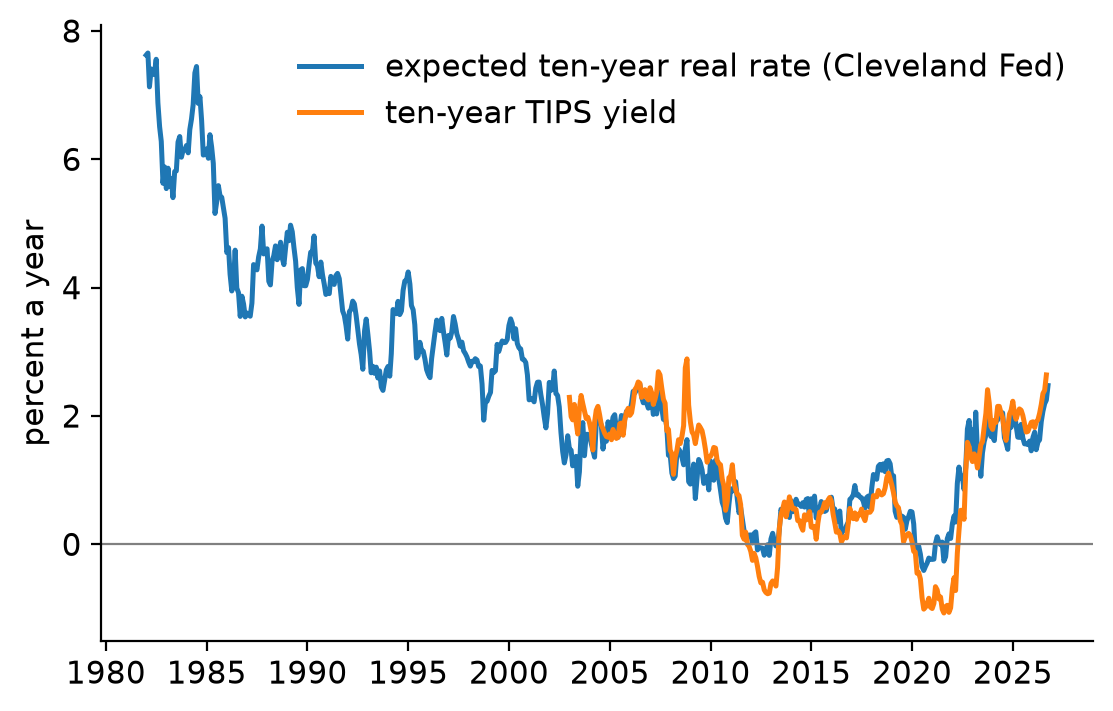

In [ ]:
fig, ax = plt.subplots()
ax.plot(expected, label="expected ten-year real rate (Cleveland Fed)")
ax.plot(tips, label="ten-year TIPS yield")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylabel("percent a year")
ax.legend()
style.save(fig, "LongTermRealRate")

## The numbers the chapter quotes

These checks stop the build if a number the chapter quotes stops matching the data.

In [ ]:
within_a_year = (expected.diff(12).dropna().abs() >= 1).mean()
within_two_years = (expected.diff(24).dropna().abs() >= 1).mean()

assert by_decade["1980s"] == 5.3 and by_decade["2010s"] == 0.6
assert round(expected.min(), 1) == -0.4 and f"{expected.idxmin():%Y-%m}" == "2020-08"
assert round(tips[low], 2) == -1.07 and f"{low:%Y-%m}" == "2021-08"
assert round(tips[high], 2) == 2.41 and f"{high:%Y-%m}" == "2023-10" and round(tips[high] - tips[low], 1) == 3.5
assert round(100 * within_a_year) == 13 and round(100 * within_two_years) == 24  # percent of months